# **Bone Fracture Detection from X-Ray Images Using CNN**

This notebook is an educational machine-learning project, not a clinically validated diagnostic tool. Test accuracy is not guaranteed to reach 90%; report the results produced by your actual run.


## 1. Environment and libraries
Run the notebook from top to bottom. This version uses EfficientNetB0 transfer learning. In Google Colab, upload the dataset ZIP as `archive.zip` first.


In [1]:
# Extract the dataset archive. Upload archive.zip to Google Colab before running this cell.
import os
import zipfile

ARCHIVE_PATH = "/content/archive.zip"
DATA_DIR = "/content/fracture_dataset"

if not os.path.isfile(ARCHIVE_PATH):
    raise FileNotFoundError(
        f"Dataset ZIP not found at {ARCHIVE_PATH}. Upload archive.zip to Colab first."
    )

os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset extracted to:", DATA_DIR)


Dataset extracted to: /content/fracture_dataset


In [2]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)
from IPython.display import display
from tensorflow.keras.utils import load_img, img_to_array

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# Find train and validation folders, even if the ZIP contains an extra parent folder.
def find_split_directory(root, split_name):
    matches = []
    for current, dirs, files in os.walk(root):
        if os.path.basename(current).lower() == split_name.lower():
            class_dirs = [d for d in dirs if not d.startswith(".")]
            if len(class_dirs) >= 2:
                matches.append(current)
    if not matches:
        raise FileNotFoundError(
            f"Could not find a '{split_name}' folder containing at least two class folders under {root}"
        )
    return matches[0]

train_dir = find_split_directory(DATA_DIR, "train")
val_dir = find_split_directory(DATA_DIR, "val")

print("Training folder:", train_dir)
print("Original validation folder:", val_dir)
print("TensorFlow version:", tf.__version__)


Training folder: /content/fracture_dataset/data/train
Original validation folder: /content/fracture_dataset/data/val
TensorFlow version: 2.21.0


In [3]:
# Load the training directory. Keras assigns class labels in alphabetical folder-name order.
train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

class_names = train_ds.class_names
if len(class_names) != 2:
    raise ValueError(f"Expected exactly two classes, found {class_names}")

# Collect individual validation images and their labels, then make a stratified split.
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
image_paths, image_labels = [], []
for label, class_name in enumerate(class_names):
    class_dir = os.path.join(val_dir, class_name)
    if not os.path.isdir(class_dir):
        raise ValueError(
            f"Class folder '{class_name}' is missing from validation directory: {val_dir}"
        )
    for root, _, files in os.walk(class_dir):
        for filename in files:
            if filename.lower().endswith(valid_extensions):
                image_paths.append(os.path.join(root, filename))
                image_labels.append(label)

image_paths = np.asarray(image_paths)
image_labels = np.asarray(image_labels, dtype=np.int32)
if len(image_paths) < 4 or len(np.unique(image_labels)) != 2:
    raise ValueError("Need at least a few validation images from both classes to split validation and test sets.")

val_paths, test_paths, val_labels, test_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.5,
    random_state=SEED,
    stratify=image_labels
)

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    # EfficientNetB0's Keras implementation includes its own rescaling.
    # Keep pixel values in the 0-255 range; do not divide by 255 here.
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)
train_ds = train_ds.prefetch(AUTOTUNE)

print("Class names (label 0 then label 1):", class_names)
print("Training image count:", sum(1 for _ in train_ds.unbatch()))
print("Validation image count:", len(val_paths), "class counts:", np.bincount(val_labels))
print("Test image count:", len(test_paths), "class counts:", np.bincount(test_labels))
print("IMPORTANT: This is a stratified split of the provided validation folder. For a final unbiased result, use a separate untouched test dataset if available.")


Found 8863 files belonging to 2 classes.
Class names (label 0 then label 1): ['fractured', 'not fractured']
Training image count: 8863
Validation image count: 300 class counts: [180 120]
Test image count: 300 class counts: [180 120]
IMPORTANT: This is a stratified split of the provided validation folder. For a final unbiased result, use a separate untouched test dataset if available.


### Dataset split note
The validation images are split by individual image with stratification, so both validation and test subsets should preserve the original class proportions. For a final unbiased result, use a separate test folder that was not used during model selection.


## 2. Check sample training images


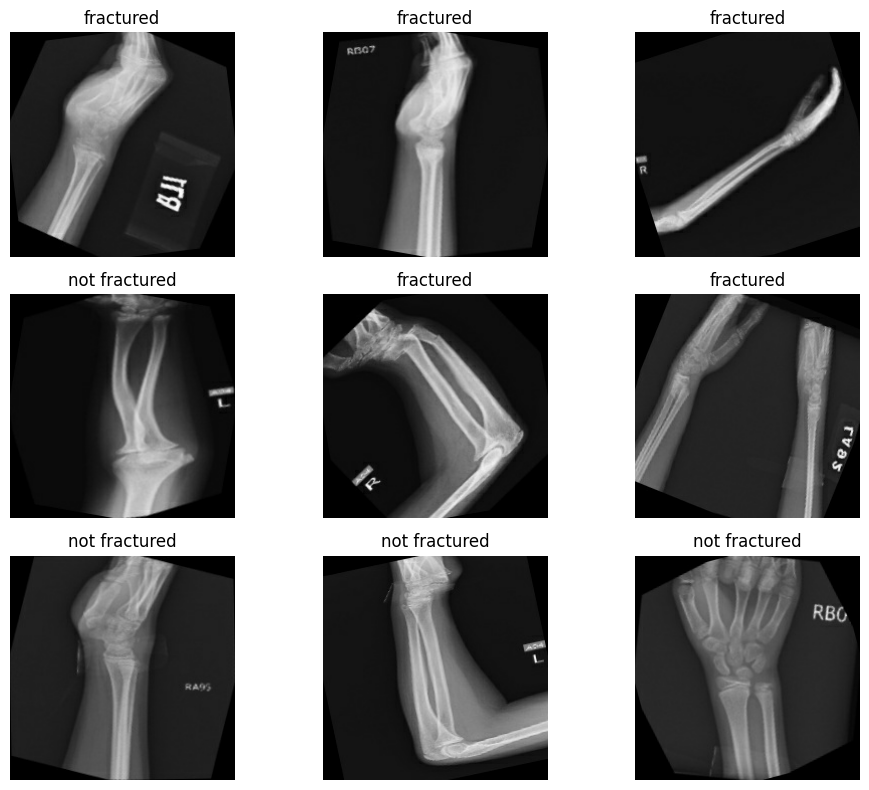

In [4]:
# Show a sample batch and its class labels.
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, int(images.shape[0]))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        label_index = int(labels[i].numpy().reshape(-1)[0] >= 0.5)
        plt.title(class_names[label_index])
        plt.axis("off")
plt.tight_layout()
plt.show()


## 3. Build the transfer-learning model


In [5]:
# EfficientNetB0 transfer learning. Initially freeze the pretrained feature extractor.
# Mild augmentation is active only during training.
augmentation = keras.Sequential([
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="bone_fracture_efficientnetb0")

metrics = [
    "accuracy",
    keras.metrics.Precision(name="precision"),
    keras.metrics.Recall(name="recall"),
    keras.metrics.AUC(name="auc")
]
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=metrics
)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "bone_fracture_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 4. Train the model in two stages


In [6]:
# Stage A: train the new classification head while the pretrained base is frozen.
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_fracture_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

# Stage B: fine-tune only the later EfficientNet layers with a much smaller learning rate.
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

# Combine histories so the existing plots show both training stages.
history = type("CombinedHistory", (), {})()
history.history = {}
for key in set(history_head.history) | set(history_finetune.history):
    history.history[key] = history_head.history.get(key, []) + history_finetune.history.get(key, [])
print("Training complete. Best validation-loss checkpoint: best_fracture_cnn.keras")


Epoch 1/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.7146 - auc: 0.7937 - loss: 0.5357 - precision: 0.7068 - recall: 0.7185
Epoch 1: val_loss improved from None to 0.53143, saving model to best_fracture_cnn.keras

Epoch 1: finished saving model to best_fracture_cnn.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 40s 93ms/step - accuracy: 0.7774 - auc: 0.8685 - loss: 0.4499 - precision: 0.7703 - recall: 0.7835 - val_accuracy: 0.7067 - val_auc: 0.7999 - val_loss: 0.5314 - val_precision: 0.6379 - val_recall: 0.6167 - learning_rate: 0.0010
Epoch 2/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8637 - auc: 0.9411 - loss: 0.3151 - precision: 0.8568 - recall: 0.8683
Epoch 2: val_loss did not improve from 0.53143
277/277 ━━━━━━━━━━━━━━━━━━━━ 21s 77ms/step - accuracy: 0.8763 - auc: 0.9508 - loss: 0.2897 - precision: 0.8714 - recall: 0.8798 - val_accuracy: 0.7200 - val_auc: 0.8114 - val_loss: 0.5417 - val_precision: 0.6765 - val_recall: 0.5750 - learning_rate: 0.0010
Epoch 3/15
277/

## 5. Training and validation accuracy


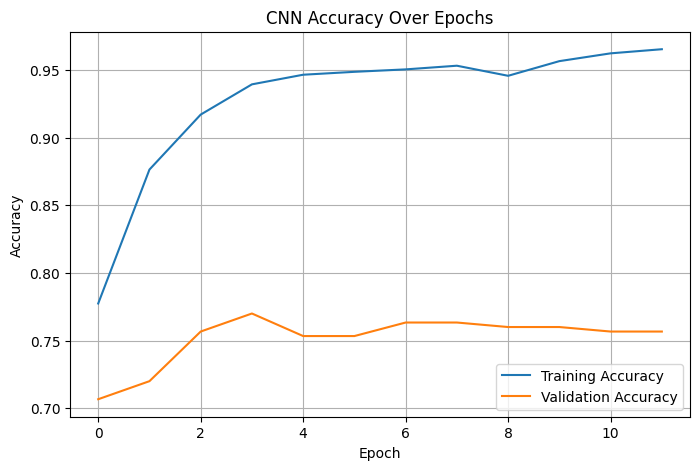

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("accuracy_curve.png", dpi=300)
plt.show()

## 6. Training and validation loss


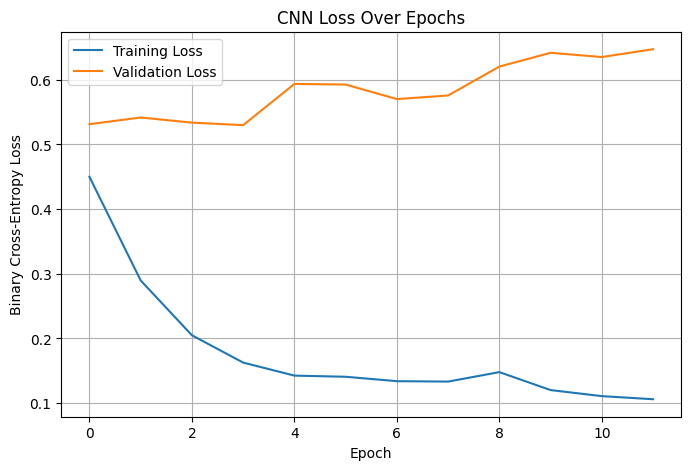

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png", dpi=300)
plt.show()

## 7. Evaluate on the test dataset


In [9]:
# Evaluate on the test subset. Do not use this result to tune the model repeatedly.
test_metrics = model.evaluate(test_ds, verbose=1, return_dict=True)
for metric_name, metric_value in test_metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")
print(f"Test accuracy: {test_metrics['accuracy'] * 100:.2f}%")


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.7000 - auc: 0.7768 - loss: 0.7377 - precision: 0.6500 - recall: 0.5417
accuracy: 0.7000
auc: 0.7768
loss: 0.7377
precision: 0.6500
recall: 0.5417
Test accuracy: 70.00%


## 8. Classification report and confusion matrix


Test accuracy: 70.00%
Fractured-class precision/recall/F1 depend on class order: class_names=['fractured', 'not fractured']

Classification report:
               precision    recall  f1-score   support

    fractured       0.72      0.81      0.76       180
not fractured       0.65      0.54      0.59       120

     accuracy                           0.70       300
    macro avg       0.69      0.67      0.68       300
 weighted avg       0.69      0.70      0.69       300



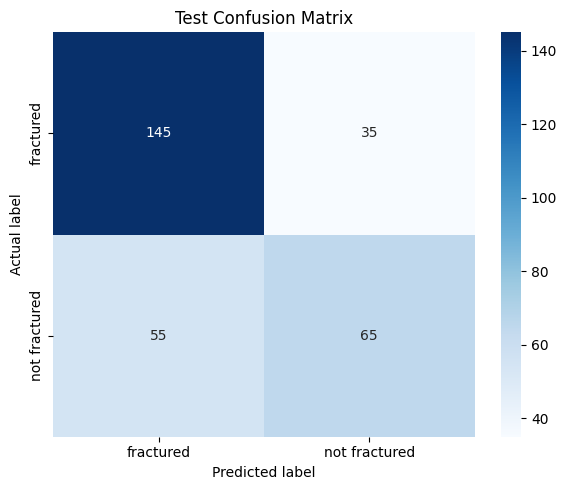

In [10]:
# test_ds is deterministic and not shuffled, so labels and predictions stay aligned.
y_true = np.concatenate([
    labels.numpy().reshape(-1).astype(int)
    for _, labels in test_ds
])
y_prob = model.predict(test_ds, verbose=0).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

if len(y_true) == 0:
    raise ValueError("The test dataset is empty. Check the dataset paths and split.")
if len(y_true) != len(y_pred):
    raise RuntimeError(f"Label count {len(y_true)} does not match prediction count {len(y_pred)}")

print(f"Test accuracy: {accuracy_score(y_true, y_pred):.2%}")
print(f"Fractured-class precision/recall/F1 depend on class order: class_names={class_names}")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=[0, 1], target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()


Predicted class: fractured
Probability for class 'not fractured': 0.0048


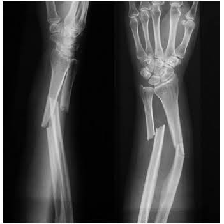

In [12]:
# Optional: upload an X-ray image to Colab and set its path here.
image_path = "/content/sample_x-ray.jpeg"

if os.path.isfile(image_path):
    img = load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
    img_array = img_to_array(img).astype("float32")  # Keep 0-255 for EfficientNetB0.
    img_array = np.expand_dims(img_array, axis=0)

    probability_class1 = float(model.predict(img_array, verbose=0)[0][0])
    predicted_index = int(probability_class1 >= 0.5)
    predicted_class = class_names[predicted_index]
    print("Predicted class:", predicted_class)
    print(f"Probability for class '{class_names[1]}': {probability_class1:.4f}")
    display(img)
else:
    print(f"Sample image not found at {image_path}. Upload an X-ray and update image_path to run prediction.")


## 9. Save the trained model


In [13]:
model.save("bone_fracture_detection_cnn.keras")
print("Model saved successfully: bone_fracture_detection_cnn.keras")


Model saved successfully: bone_fracture_detection_cnn.keras
